# Superstore Sales & Profitability Analysis
**Tools:** Python, Pandas, Matplotlib | **Data:** Superstore Sales (Kaggle), 9,994 orders, 2014-2017

**Business questions**
1. Which product / sub-category generates the maximum profit?
2. Which state has the most losses?
3. How does late delivery affect profit?
4. How does discount affect profit?

## 1. Import Libraries & Load Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams["figure.figsize"] = (10, 5)

# The CSV file must be in the same folder as this notebook
df = pd.read_csv("Sample - Superstore.csv", encoding="ISO-8859-1")
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.87
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5,0.45,-383.03
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2,0.20,2.52


## 2. Data Understanding & Cleaning

In [2]:
print("Shape:", df.shape)
df.info()

Shape: (9994, 21)
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Q

In [3]:
print("Null values :", df.isnull().sum().sum())
print("Duplicates  :", df.duplicated().sum())

# Convert date columns to datetime type
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"]  = pd.to_datetime(df["Ship Date"])

Null values : 0
Duplicates  : 0


## 3. Feature Creation (P&L logic)

In [4]:
df["Delivery Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Margin %"]      = df["Profit"] / df["Sales"] * 100
df["Year"]          = df["Order Date"].dt.year
df["Month"]         = df["Order Date"].dt.to_period("M").astype(str)
df["Late"] = df["Delivery Days"].apply(lambda d: "Late (6-7 days)" if d >= 6 else "On time (0-5 days)")
df["Discount Bucket"] = pd.cut(df["Discount"], [-0.01, 0, 0.2, 0.4, 1],
                               labels=["0%", "1-20%", "21-40%", "40%+"])
df[["Order Date","Ship Date","Delivery Days","Sales","Profit","Margin %"]].head()

,Order Date,Ship Date,Delivery Days,Sales,Profit,Margin %
0,2016-11-08,2016-11-11,3,261.96,41.91,16.00
1,2016-11-08,2016-11-11,3,731.94,219.58,30.00
2,2016-06-12,2016-06-16,4,14.62,6.87,47.00
3,2015-10-11,2015-10-18,7,957.58,-383.03,-40.00
4,2015-10-11,2015-10-18,7,22.37,2.52,11.25


## 4. Overall KPIs

In [5]:
total_sales  = df["Sales"].sum()
total_profit = df["Profit"].sum()
print(f"Total Sales  : ${total_sales:,.0f}")
print(f"Total Profit : ${total_profit:,.0f}")
print(f"Profit Margin: {total_profit/total_sales:.2%}")
print(f"Total Orders : {df['Order ID'].nunique():,}")

Total Sales  : $2,297,201
Total Profit : $286,397
Profit Margin: 12.47%
Total Orders : 5,009


## 5. Q1: Which product generates the maximum profit?

In [6]:
prod = df.groupby("Product Name")["Profit"].sum().sort_values(ascending=False)
print("TOP 5 PRODUCTS"); print(prod.head(5)); print()
print("BOTTOM 5 PRODUCTS (loss)"); print(prod.tail(5))

TOP 5 PRODUCTS
Product Name
Canon imageCLASS 2200 Advanced Copier                                         25,199.93
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    7,753.04
Hewlett Packard LaserJet 3310 Copier                                           6,983.88
Canon PC1060 Personal Laser Copier                                             4,570.93
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      4,094.98
Name: Profit, dtype: float64

BOTTOM 5 PRODUCTS (loss)
Product Name
Bush Advantage Collection Racetrack Conference Table       -1,934.40
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases   -2,876.12
Cubify CubeX 3D Printer Triple Head Print                  -3,839.99
Lexmark MX611dhe Monochrome Laser Printer                  -4,589.97
Cubify CubeX 3D Printer Double Head Print                  -8,879.97
Name: Profit, dtype: float64


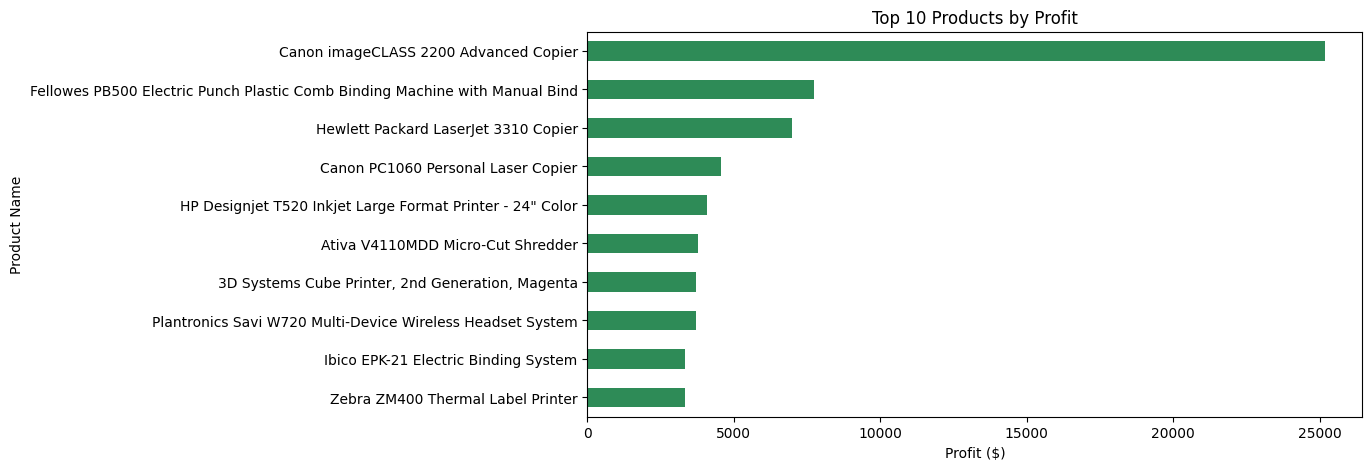

In [7]:
prod.head(10)[::-1].plot(kind="barh", color="seagreen", title="Top 10 Products by Profit")
plt.xlabel("Profit ($)"); plt.show()

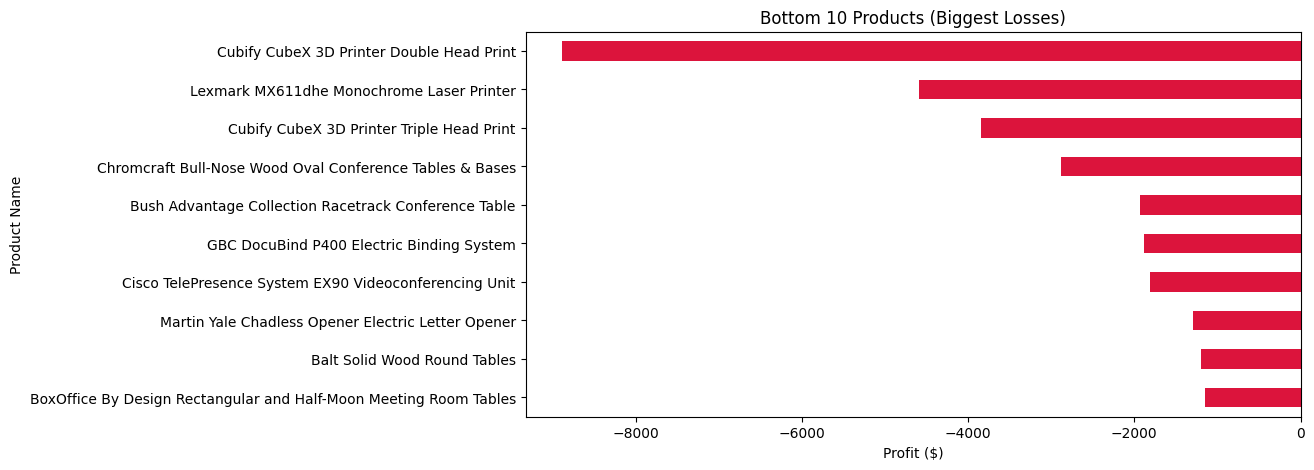

In [8]:
prod.tail(10).plot(kind="barh", color="crimson", title="Bottom 10 Products (Biggest Losses)")
plt.xlabel("Profit ($)"); plt.show()

### Sub-Category: Sales vs Profit

In [9]:
sub = df.groupby("Sub-Category")[["Sales","Profit"]].sum().sort_values("Profit")
sub["Margin %"] = sub["Profit"] / sub["Sales"] * 100
sub

,Sales,Profit,Margin %
Sub-Category,,,
Tables,"206,965.53","-17,725.48",-8.56
Bookcases,"114,880.00","-3,472.56",-3.02
Supplies,"46,673.54","-1,189.10",-2.55
Fasteners,"3,024.28",949.52,31.40
Machines,"189,238.63","3,384.76",1.79
Labels,"12,486.31","5,546.25",44.42
Art,"27,118.79","6,527.79",24.07
Envelopes,"16,476.40","6,964.18",42.27
Furnishings,"91,705.16","13,059.14",14.24


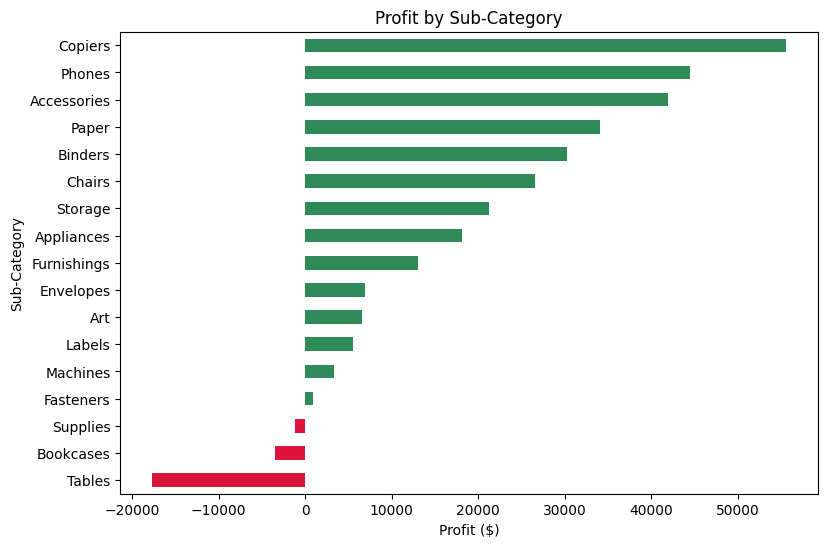

In [10]:
sub["Profit"].plot(kind="barh", figsize=(9,6),
                   color=["crimson" if v < 0 else "seagreen" for v in sub["Profit"]],
                   title="Profit by Sub-Category")
plt.xlabel("Profit ($)"); plt.show()

**Insight:** Tables have high sales but negative profit. High sales do not necessarily mean high profit.

## 6. Q2: Which state has the most losses?

In [11]:
state = df.groupby("State")[["Sales","Profit"]].sum().sort_values("Profit")
state.head(10)

,Sales,Profit
State,,
Texas,"170,188.05","-25,729.36"
Ohio,"78,258.14","-16,971.38"
Pennsylvania,"116,511.91","-15,559.96"
Illinois,"80,166.10","-12,607.89"
North Carolina,"55,603.16","-7,490.91"
Colorado,"32,108.12","-6,527.86"
Tennessee,"30,661.87","-5,341.69"
Arizona,"35,282.00","-3,427.92"
Florida,"89,473.71","-3,399.30"


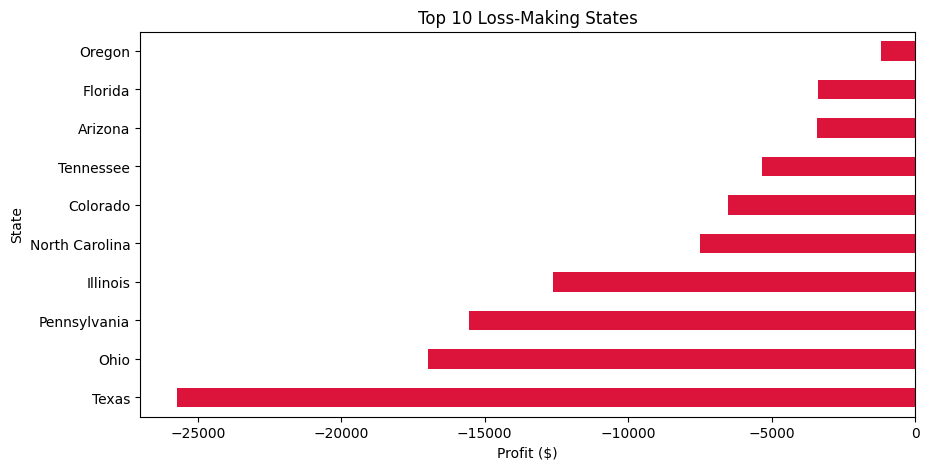

In [12]:
state["Profit"].head(10).plot(kind="barh", color="crimson", title="Top 10 Loss-Making States")
plt.xlabel("Profit ($)"); plt.show()

In [13]:
print("Profitable states :", (state["Profit"] > 0).sum())
print("Loss-making states:", (state["Profit"] < 0).sum())

Profitable states : 39
Loss-making states: 10


## 7. Q3: Late delivery vs Profit

In [14]:
dd = df.groupby("Delivery Days")["Profit"].agg(["mean","sum","count"])
dd

,mean,sum,count
Delivery Days,,,
0,29.65,"15,385.97",519
1,20.44,"7,541.23",369
2,39.82,"53,118.11",1334
3,26.74,"26,875.92",1005
4,25.64,"71,134.77",2774
5,27.08,"58,733.20",2169
6,27.66,"33,275.97",1203
7,32.74,"20,331.85",621


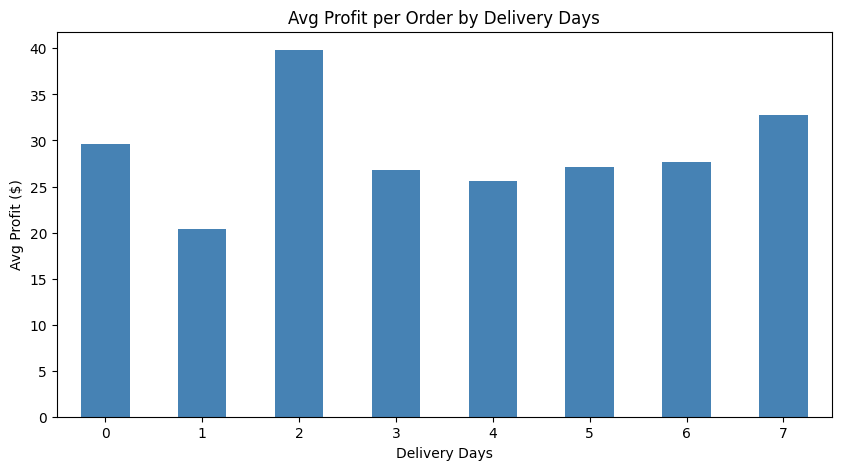

In [15]:
dd["mean"].plot(kind="bar", color="steelblue", title="Avg Profit per Order by Delivery Days")
plt.xlabel("Delivery Days"); plt.ylabel("Avg Profit ($)"); plt.xticks(rotation=0); plt.show()

In [16]:
print(df.groupby("Late")[["Profit","Margin %"]].mean())
print()
print("Correlation (Delivery Days vs Profit):", round(df["Delivery Days"].corr(df["Profit"]), 4))
print()
print(df.groupby("Ship Mode")[["Delivery Days","Profit"]].mean())

                    Profit  Margin %
Late                                
Late (6-7 days)      29.39     12.53
On time (0-5 days)   28.49     11.92

Correlation (Delivery Days vs Profit): -0.0046

                Delivery Days  Profit
Ship Mode                            
First Class              2.18   31.84
Same Day                 0.04   29.27
Second Class             3.24   29.54
Standard Class           5.01   27.49


**Insight:** The correlation is almost 0, so late delivery has no meaningful impact on profit.

## 8. Q4: Discount vs Profit

In [17]:
disc = df.groupby("Discount Bucket", observed=True)["Profit"].agg(["sum","mean","count"])
disc

,sum,mean,count
Discount Bucket,,,
0%,"320,987.60",66.90,4798
1-20%,"100,785.47",26.50,3803
21-40%,"-35,817.47",-77.86,460
40%+,"-99,558.59",-106.71,933


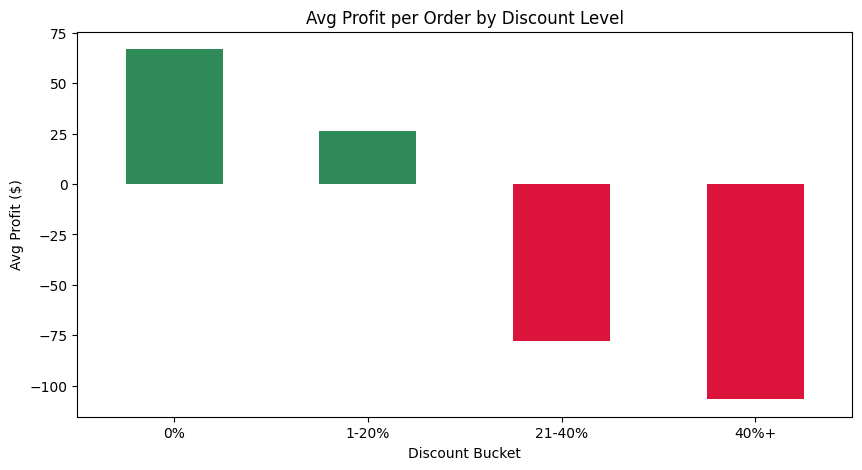

In [18]:
disc["mean"].plot(kind="bar", color=["seagreen" if v > 0 else "crimson" for v in disc["mean"]],
                  title="Avg Profit per Order by Discount Level")
plt.ylabel("Avg Profit ($)"); plt.xticks(rotation=0); plt.show()

**Insight:** Orders with a discount above 20% turn loss-making. Discounting is the real profit problem.

## 9. Region, Segment & Monthly Trend

In [19]:
df.groupby("Region")[["Sales","Profit"]].sum()

,Sales,Profit
Region,,
Central,"501,239.89","39,706.36"
East,"678,781.24","91,522.78"
South,"391,721.91","46,749.43"
West,"725,457.82","108,418.45"


In [20]:
df.groupby("Segment")[["Sales","Profit"]].sum()

,Sales,Profit
Segment,,
Consumer,"1,161,401.34","134,119.21"
Corporate,"706,146.37","91,979.13"
Home Office,"429,653.15","60,298.68"


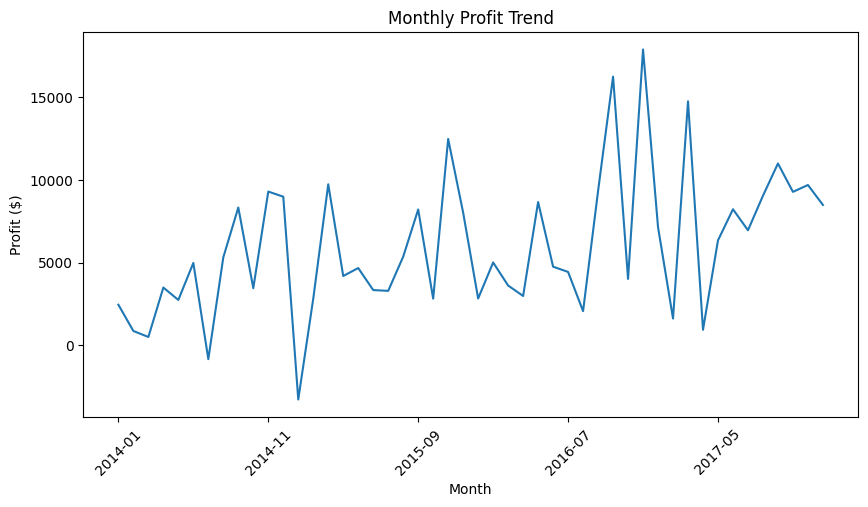

In [21]:
monthly = df.groupby("Month")[["Sales","Profit"]].sum()
monthly["Profit"].plot(title="Monthly Profit Trend")
plt.ylabel("Profit ($)"); plt.xticks(rotation=45); plt.show()

## 10. Conclusion & Recommendations
- The overall margin is only ~12.5%, and heavy discounting is a major reason.
- **Tables, Bookcases and Supplies** are loss-making; review their pricing and discount policy.
- **Texas, Ohio, Pennsylvania and Illinois** are the most loss-making states.
- No relationship was found between late delivery and profit, so focus on controlling discounts.
- **Recommendation:** Cap discounts at 20%.

## 11. Resume Bullets (auto-filled)

In [22]:
top_prod, top_prod_p = prod.index[0], prod.iloc[0]
worst_state, worst_state_p = state.index[0], state["Profit"].iloc[0]
neg_sub = ", ".join(sub[sub["Profit"] < 0].index[::-1])
y0, y1 = df["Year"].min(), df["Year"].max()
corr = df["Delivery Days"].corr(df["Profit"])

print(f"- Analysed {len(df):,} retail transactions ({y0}-{y1}) using Python (Pandas, Matplotlib): sales ${total_sales/1e6:.2f}M, profit ${total_profit/1e3:.0f}K, margin {total_profit/total_sales:.2%}.")
print(f"- Identified {top_prod} as the top profit product (${top_prod_p/1e3:.1f}K), {worst_state} as the most loss-making state (-${abs(worst_state_p)/1e3:.1f}K) and loss-making sub-categories: {neg_sub}.")
print(f"- Found that orders with 21%+ discount lose money (avg ${disc['mean'].iloc[2]:.0f} to ${disc['mean'].iloc[3]:.0f} per order) versus +${disc['mean'].iloc[0]:.0f} at 0% discount.")
print(f"- Tested delivery delay vs profit (correlation {corr:.3f}, no significant impact) and recommended a 20% discount cap.")

- Analysed 9,994 retail transactions (2014-2017) using Python (Pandas, Matplotlib): sales $2.30M, profit $286K, margin 12.47%.
- Identified Canon imageCLASS 2200 Advanced Copier as the top profit product ($25.2K), Texas as the most loss-making state (-$25.7K) and loss-making sub-categories: Supplies, Bookcases, Tables.
- Found that orders with 21%+ discount lose money (avg $-78 to $-107 per order) versus +$67 at 0% discount.
- Tested delivery delay vs profit (correlation -0.005, no significant impact) and recommended a 20% discount cap.
